# Safety analysis of the transition from Level 2 to Level 3 driving automation
**Hari Pavan Bakkamanthala | 7033SCN | Coventry University**

This notebook contains and executes the analysis code directly. The original datasets were published by NTSB and NHTSA. The single detailed incident is Uber Tempe. The separate NHTSA ADS cohort is not a Level 2 versus Level 3 comparison.

Run all cells in order from the repository root, with the `uber_tempe` and `nhtsa` folders beside this notebook. Saved outputs are included. Running the notebook regenerates derived CSV/JSON files and charts in these project folders. It never modifies the original data files. See README.md, data_sources.json and CORRECTIONS.md for provenance and limitations.

## 1 Setup and source verification

In [1]:
from pathlib import Path
import json
import hashlib
from IPython.display import Image, display
NB_ROOT = Path.cwd()
required = [
    NB_ROOT / "uber_tempe/original_ntsb_attachment.csv",
    NB_ROOT / "nhtsa/NHTSA_ADS_archive_raw.csv",
]
for path in required:
    assert path.is_file(), f"Missing input: {path.name}; open from the repository root"
    print(path.relative_to(NB_ROOT), hashlib.sha256(path.read_bytes()).hexdigest())


uber_tempe/original_ntsb_attachment.csv be2acba62e8e963850bf04dadbbdc3640d8172c8a71a4bb3b592bdc2d9fa592f
nhtsa/NHTSA_ADS_archive_raw.csv cb2b38a21e2ce5c2337dfa0cffe8d6fce5e422cf93fe4c78942eec5cf72f41ba


## 2 Case data acquisition cleaning and preparation
The recorder CSV includes preamble rows and separate vehicle and gaze streams. Source row numbers preserve traceability. Numeric gaps remain missing, shared timestamps are retained and uncertain transition gaps are not assigned a gaze state.

The next cells contain the recorder program, adapted only to use notebook paths rather than `__file__`.

In [2]:
from pathlib import Path
import csv, io, json, hashlib, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = NB_ROOT / 'uber_tempe'
OUT = ROOT / 'Uber_Tempe_Analysis'
OUT.mkdir(exist_ok=True)
srcs = list((ROOT / 'upload').glob('Attachment 1*.csv')) if (ROOT / 'upload').exists() else []
SOURCE = srcs[0] if srcs else ROOT / 'original_ntsb_attachment.csv'
raw = SOURCE.read_bytes()
shutil.copyfile(SOURCE, OUT / 'original_ntsb_attachment.csv')
rows = list(csv.reader(io.StringIO(raw.decode('utf-8-sig'))))
header = next(i for i,r in enumerate(rows) if r[0].strip() == 'Time')
start = next(i for i in range(header+1,len(rows)) if ':' in rows[i][0])
names = ['time_raw','heading_deg','speed_mph','gsensor_x_raw','gsensor_y_raw','gsensor_z_raw','gaze_event']
d = pd.DataFrame(rows[start:], columns=names)
d.insert(0, 'source_csv_row', np.arange(start+1,len(rows)+1))
for col in names: d[col] = d[col].str.strip().replace('',pd.NA)
# Decimal tenths avoid binary rounding when comparing the source timestamps.
def ticks(s):
    minutes,seconds = s.split(':')
    whole,frac = (seconds+'.0').split('.')[:2]
    return int(minutes)*600 + int(whole)*10 + int(frac[0])
d['time_tenths_within_hour'] = d.time_raw.map(ticks)
d['time_s_within_hour'] = d.time_tenths_within_hour/10
IMPACT = 35265  # 21:58:46.5 MST, recorder report; alignment uncertainty about +/-0.5 s.
d['time_relative_impact_s'] = (d.time_tenths_within_hour-IMPACT)/10
for col in names[1:]: d[col] = pd.to_numeric(d[col],errors='raise')
assert not d.time_raw.isna().any()
assert d.time_tenths_within_hour.is_monotonic_increasing
assert d.gaze_event.dropna().isin([0,1]).all()
assert d.speed_mph.dropna().ge(0).all()
assert d.heading_deg.dropna().between(0,360).all()
d.to_csv(OUT/'cleaned_source_rows.csv',index=False)
t = d[d.speed_mph.notna()].copy()
g = d[d.gaze_event.notna()][['source_csv_row','time_raw','time_tenths_within_hour','time_s_within_hour','time_relative_impact_s','gaze_event']].copy()
assert np.all(np.diff(t.time_tenths_within_hour)==5)
assert not t.time_tenths_within_hour.duplicated().any()
t.to_csv(OUT/'vehicle_samples.csv',index=False)
g.to_csv(OUT/'gaze_events_preserved.csv',index=False)


In [3]:
# Consecutive equal-state points delimit explicitly documented gaze spans.
# A gap between different states is retained as uncertain, not assigned automatically.
run = (g.gaze_event != g.gaze_event.shift()).cumsum()
intervals = g.groupby(run,sort=False).agg(start_tick=('time_tenths_within_hour','first'),end_tick=('time_tenths_within_hour','last'),gaze=('gaze_event','first'),first_source_row=('source_csv_row','first'),last_source_row=('source_csv_row','last')).reset_index(drop=True)
intervals['duration_s'] = (intervals.end_tick-intervals.start_tick)/10
intervals['gaze_label'] = intervals.gaze.map({0:'Downward',1:'Upward'})
intervals.to_csv(OUT/'gaze_intervals_explicit.csv',index=False)
gaps = []
for a,b in zip(intervals.itertuples(),intervals.iloc[1:].itertuples()):
    if b.start_tick>a.end_tick:
        gaps.append({'start_tick':a.end_tick,'end_tick':b.start_tick,'duration_s':(b.start_tick-a.end_tick)/10})
pd.DataFrame(gaps,columns=['start_tick','end_tick','duration_s']).to_csv(OUT/'gaze_transition_gaps.csv',index=False)


### Full-trip checks and descriptive plots
The full-trip moving downward-gaze percentage does **not** reproduce the published 34.1%; it is retained as an unresolved diagnostic, not a validated report finding. The source acceleration channels are not used to infer braking. This one incident does not supply independent samples of drivers or crashes.

In [4]:
# Time weighting: speed is held to the next 0.5-second sample for movement classification.
# This is an explicit analysis assumption, not an extra measured speed.
lo,hi = int(g.time_tenths_within_hour.min()),int(g.time_tenths_within_hour.max())
edges=np.unique(np.r_[lo,hi,t.time_tenths_within_hour.to_numpy(),g.time_tenths_within_hour.to_numpy()])
edges=edges[(edges>=lo)&(edges<=hi)]
left,right=edges[:-1],edges[1:]
mid=(left+right)/2
ti=np.searchsorted(t.time_tenths_within_hour.to_numpy(),mid,side='right')-1
moving=t.speed_mph.to_numpy(dtype=float)[ti]>0
state=np.full(len(mid),np.nan)
for row in intervals.itertuples():
    state[(mid>=row.start_tick)&(mid<row.end_tick)] = row.gaze
dur=(right-left)/10
known=np.isfinite(state)
summary=[]
for label,mask in [('All gaze coverage',np.ones(len(mid),dtype=bool)),('Moving within gaze coverage',moving),('Stopped within gaze coverage',~moving)]:
    total=float(dur[mask].sum());down=float(dur[mask&(state==0)].sum());up=float(dur[mask&(state==1)].sum());unknown=float(dur[mask&~known].sum())
    summary.append(dict(period=label,total_s=total,downward_s=down,upward_s=up,transition_unknown_s=unknown,downward_pct_total=100*down/total,downward_pct_known=100*down/(down+up)))
summary=pd.DataFrame(summary)
summary.to_csv(OUT/'duration_summary.csv',index=False)
# Alternative boundary convention for sensitivity only: last row at a tied time
# becomes the state until the next timestamp. Preserve the original events above.
unique_g=g.drop_duplicates('time_tenths_within_hour',keep='last')
gi=np.searchsorted(unique_g.time_tenths_within_hour.to_numpy(),mid,side='right')-1
held=unique_g.gaze_event.to_numpy(dtype=float)[gi]
audit={
 'validation_status':'PROVISIONAL: moving downward-gaze estimate does not reproduce NTSB published 34.1%; reconcile before using that aggregate as a final finding.',
 'case':'HWY18MH010; Uber Tempe; 18 March 2018',
 'source_sha256':hashlib.sha256(raw).hexdigest(),
 'csv_physical_rows':len(rows),'preamble_header_and_units_rows_excluded':start,
 'data_rows_retained':len(d),'vehicle_sample_rows':len(t),'gaze_event_rows':len(g),
 'rows_containing_both_streams':int((d.speed_mph.notna()&d.gaze_event.notna()).sum()),
 'exact_duplicate_data_rows':int(d[names].duplicated().sum()),
 'additional_rows_sharing_a_timestamp':int(d.time_tenths_within_hour.duplicated().sum()),
 'rows_deleted_as_duplicates':0,'vehicle_sample_interval_s':0.5,
 'vehicle_record_duration_s':float((t.time_tenths_within_hour.iloc[-1]-t.time_tenths_within_hour.iloc[0])/10),
 'gaze_coverage_duration_s':(hi-lo)/10,
 'gaze_transition_gaps_count':len(gaps),'gaze_transition_gaps_s':sum(x['duration_s'] for x in gaps),
 'strict_moving_downward_pct':float(summary.loc[1,'downward_pct_total']),
 'alternative_last_state_hold_moving_downward_pct':float(100*dur[moving&(held==0)].sum()/dur[moving].sum()),
 'ntsb_reported_moving_downward_pct':34.1,
 'numeric_conversion_failures':0,
 'gaze_note':'Up/down orientation only; not a validated measure of phone use, comprehension, trust or workload.',
 'timing_note':'MM:SS.s within the 21:00 MST hour, inferred from recorder report; not trip elapsed seconds. Impact alignment uncertainty about +/-0.5 s.',
 'acceleration_note':'Source axes retained unchanged; unreliable baseline identified by NTSB; excluded from braking-performance inference.',
 'statistical_note':'One driver and one crash; rows and gaze episodes are temporally dependent. No Pearson chi-square significance claim.'
}
(OUT/'cleaning_audit.json').write_text(json.dumps(audit,indent=2))
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(t.time_relative_impact_s,t.speed_mph,lw=1,color='#315e87')
ax.axvline(0,color='#a83232',ls='--',label='Impact reference')
ax.set(xlabel='Seconds relative to impact reference',ylabel='GPS-derived speed (mph)',title='Uber Tempe vehicle speed during the recorded trip')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();fig.savefig(OUT/'01_vehicle_speed.png',dpi=180);plt.close(fig)
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(10,5.5),sharex=True,gridspec_kw={'height_ratios':[2,1]})
ax1.plot(t.time_relative_impact_s,t.speed_mph,color='#315e87')
ax1.set(ylabel='GPS speed (mph)',title='Vehicle speed and coded gaze in the final 30 seconds')
for row in intervals.itertuples():
    a,b=(row.start_tick-IMPACT)/10,(row.end_tick-IMPACT)/10
    ax2.broken_barh([(a,b-a)],(-.35,.7),facecolors='#b74848' if row.gaze==0 else '#437c6b')
for ax in [ax1,ax2]: ax.axvline(0,color='black',ls='--',lw=.8);ax.set_xlim(-30,0);ax.grid(axis='x',alpha=.2)
ax2.set(yticks=[],ylabel='Gaze',xlabel='Seconds relative to impact reference')
from matplotlib.patches import Patch
ax2.legend(handles=[Patch(color='#b74848',label='Downward'),Patch(color='#437c6b',label='Upward'),Patch(facecolor='white',edgecolor='gray',label='Uncertain transition gap')],loc='upper left',bbox_to_anchor=(0,-.4),ncol=3)
fig.tight_layout();fig.savefig(OUT/'02_preimpact_speed_and_gaze.png',dpi=180,bbox_inches='tight');plt.close(fig)
print(json.dumps(audit,indent=2));print(summary.to_string(index=False))


{
  "validation_status": "PROVISIONAL: moving downward-gaze estimate does not reproduce NTSB published 34.1%; reconcile before using that aggregate as a final finding.",
  "case": "HWY18MH010; Uber Tempe; 18 March 2018",
  "source_sha256": "be2acba62e8e963850bf04dadbbdc3640d8172c8a71a4bb3b592bdc2d9fa592f",
  "csv_physical_rows": 6016,
  "preamble_header_and_units_rows_excluded": 13,
  "data_rows_retained": 6003,
  "vehicle_sample_rows": 4901,
  "gaze_event_rows": 1192,
  "rows_containing_both_streams": 90,
  "exact_duplicate_data_rows": 0,
  "additional_rows_sharing_a_timestamp": 477,
  "rows_deleted_as_duplicates": 0,
  "vehicle_sample_interval_s": 0.5,
  "vehicle_record_duration_s": 2450.0,
  "gaze_coverage_duration_s": 2328.8,
  "gaze_transition_gaps_count": 186,
  "gaze_transition_gaps_s": 18.6,
  "strict_moving_downward_pct": 29.915663289662124,
  "alternative_last_state_hold_moving_downward_pct": 30.30817376544847,
  "ntsb_reported_moving_downward_pct": 34.1,
  "numeric_conversio

## 3 Validated final window and Matplotlib chart
Restrict the explicit downward intervals to the final 166.5 seconds. The published comparator is 23 episodes and 58.43 seconds (Payne, 2019). Agreement at source precision validates this window only.

In [5]:
from pathlib import Path
import json
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
ROOT = NB_ROOT / "uber_tempe"
OUT = ROOT / "Uber_Tempe_Analysis"
g = pd.read_csv(OUT / "gaze_intervals_explicit.csv")
impact_tick = 35265
start_tick = impact_tick - 1665
g = g.loc[(g.gaze == 0) & (g.end_tick > start_tick) & (g.start_tick < impact_tick)].copy()
g["start_tick"] = g.start_tick.clip(lower=start_tick)
g["end_tick"] = g.end_tick.clip(upper=impact_tick)
g["duration_s"] = (g.end_tick - g.start_tick) / 10
g.to_csv(OUT / "final_window_glances.csv", index=False)
summary = {"window_s":166.5,"episodes":len(g),"total_downward_s":float(g.duration_s.sum()),"mean_s":float(g.duration_s.mean()),"median_s":float(g.duration_s.median()),"maximum_s":float(g.duration_s.max())}
(OUT / "final_window_summary.json").write_text(json.dumps(summary, indent=2))
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
ax.bar(range(1,len(g)+1),g.duration_s,color="#21618c")
ax.set(xlabel="Downward gaze episode",ylabel="Duration (seconds)",title="Final 166.5 seconds: explicit downward gaze intervals")
fig.savefig(OUT / "03_final_window_glances.png",dpi=180)
plt.close(fig)
print(json.dumps(summary,indent=2))


{
  "window_s": 166.5,
  "episodes": 23,
  "total_downward_s": 58.39999999999999,
  "mean_s": 2.5391304347826082,
  "median_s": 2.2,
  "maximum_s": 6.9
}


Verified final window: {'window_s': 166.5, 'episodes': 23, 'total_downward_s': 58.39999999999999, 'mean_s': 2.5391304347826082, 'median_s': 2.2, 'maximum_s': 6.9}


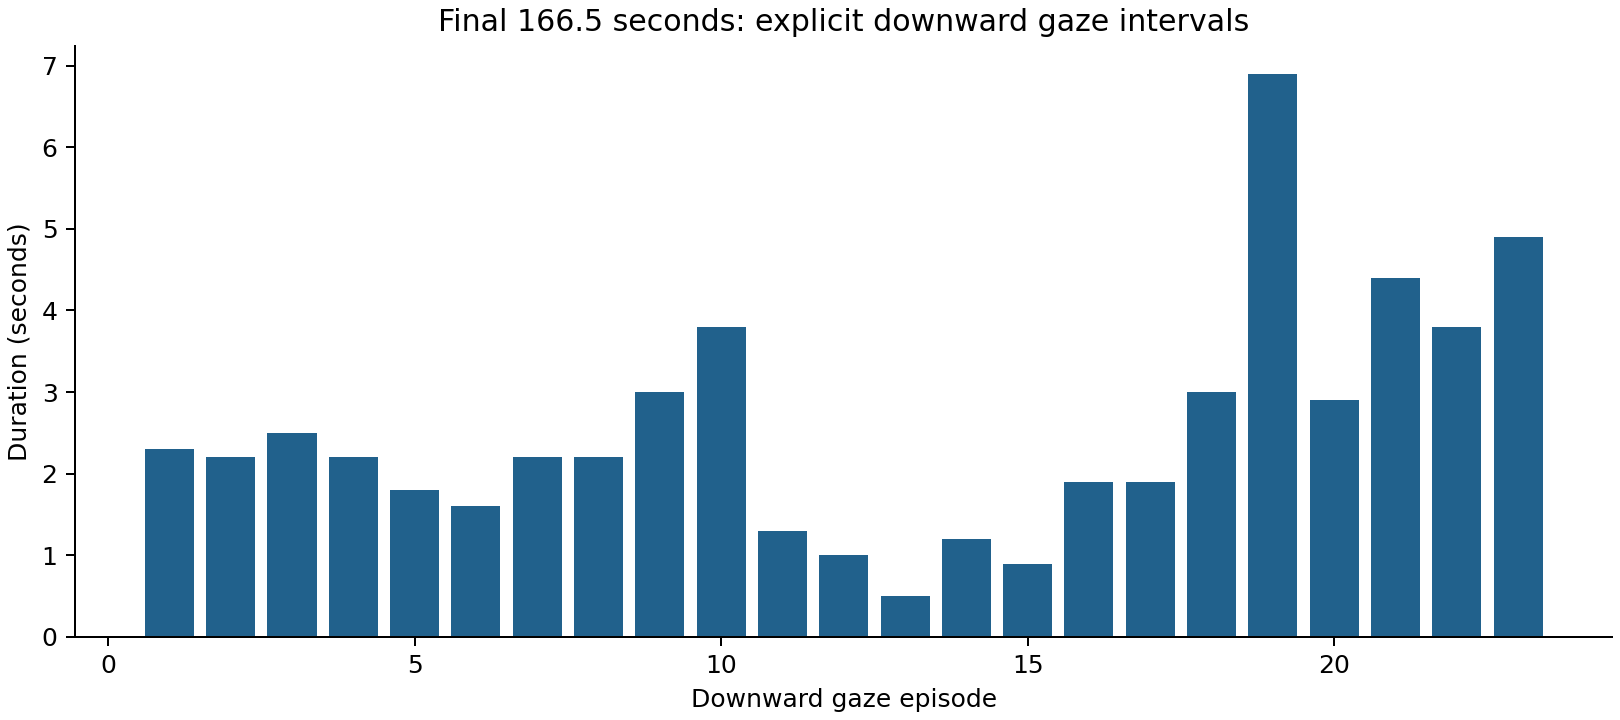

In [6]:
window = json.loads((NB_ROOT / "uber_tempe/Uber_Tempe_Analysis/final_window_summary.json").read_text())
assert window["episodes"] == 23
assert abs(window["total_downward_s"] - 58.4) < 1e-8
print("Verified final window:", window)
display(Image(filename=str(NB_ROOT / "uber_tempe/Uber_Tempe_Analysis/03_final_window_glances.png")))


## 4 Supplementary NHTSA acquisition and cleaning
The analysis selects in-vehicle-only and remote-only commercial/test operators. Preserve the valid literal category `None`; an empty string is a different value. Latest versions and incident grouping reduce duplicate report counting. Exclusions are recorded rather than silently discarded.

In [7]:
"""Exploratory incident-level association, not a causal or Level 2-vs-3 safety test.
Run in Colab or locally: python analyse_nhtsa.py
Dependencies: pandas, numpy, scipy, matplotlib (already included in Colab).
"""
from pathlib import Path
import hashlib
import json
import platform
import urllib.request

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.stats import chi2_contingency, fisher_exact

ROOT = NB_ROOT / "nhtsa"
SOURCE = 'https://static.nhtsa.gov/odi/ffdd/sgo-2021-01/Archive-2021-2025/SGO-2021-01_Incident_Reports_ADS.csv'
RAW = ROOT / 'NHTSA_ADS_archive_raw.csv'
if not RAW.exists():
    urllib.request.urlretrieve(SOURCE, RAW)

raw = pd.read_csv(RAW, low_memory=False, keep_default_na=False)
d = raw.copy()
for c in d.select_dtypes('object'):
    d[c] = d[c].str.strip().replace('', pd.NA)
assert d['Report ID'].notna().all(), 'Missing Report ID requires manual review.'
d['Report Version'] = pd.to_numeric(d['Report Version'], errors='raise')
assert not d.duplicated(['Report ID', 'Report Version']).any(), 'Tied versions require manual review.'
latest = d.sort_values(['Report ID', 'Report Version']).drop_duplicates('Report ID', keep='last').copy()
latest['incident_key'] = latest['Same Incident ID'].fillna('REPORT:' + latest['Report ID'])

INJURY = {'Minor', 'Moderate', 'Serious', 'Fatality'}
GROUP_MAP = {
    'In-Vehicle (Commercial / Test)': 'In-vehicle only',
    'Remote (Commercial / Test)': 'Remote only',
}
def unique_values(s):
    return sorted(set(s.dropna().astype(str)))



In [8]:
# Do not resolve conflicting reports by arbitrarily choosing one reporting entity.
# Exclude cases with missing required fields in ANY of their latest reports.
records = []
for key, g in latest.groupby('incident_key', sort=True):
    modes = unique_values(g['Automation System Engaged?'])
    operators = unique_values(g['Driver / Operator Type'])
    outcomes = g['Highest Injury Severity Alleged'].map(
        lambda v: 'Injury reported' if pd.notna(v) and v in INJURY
        else ('No injuries reported' if v == 'No Injuries Reported' else 'Unknown'))
    outcome_values = unique_values(outcomes)
    reason = 'Included'
    if g['Automation System Engaged?'].isna().any() or modes != ['ADS']:
        reason = 'Engagement not consistently ADS'
    elif g['Same Incident ID'].isna().any():
        reason = 'Incident identifier missing; duplication cannot be checked'
    elif g['Driver / Operator Type'].isna().any():
        reason = 'Operator category missing'
    elif len(operators) != 1:
        reason = 'Operator categories disagree across reports'
    elif operators[0] not in GROUP_MAP:
        reason = 'Operator category outside the two specified groups'
    elif 'Unknown' in outcome_values:
        reason = 'Injury outcome missing or unknown'
    elif len(outcome_values) != 1:
        reason = 'Binary injury outcomes disagree across reports'
    vehicles = unique_values(g['Same Vehicle ID'])
    records.append({
        'incident_key': key,
        'report_ids': ' | '.join(unique_values(g['Report ID'])),
        'reporting_entities': ' | '.join(unique_values(g['Reporting Entity'])),
        'incident_dates': ' | '.join(unique_values(g['Incident Date'])),
        'operator_categories': ' | '.join(operators),
        'injury_categories': ' | '.join(unique_values(g['Highest Injury Severity Alleged'])),
        'operator_group': GROUP_MAP.get(operators[0], '') if len(operators) == 1 else '',
        'injury_outcome': outcome_values[0] if len(outcome_values) == 1 else '',
        'vehicle_ids': ' | '.join(vehicles),
        'same_incident_id_missing': g['Same Incident ID'].isna().any(),
        'decision': reason,
    })


## 5 Descriptive counts and chi-square test
H0: operator category and reported injury outcome are independent in the included records. H1: they are associated. Expected counts are checked before interpretation. The code computes Pearson chi-square, Cramer’s V and supplementary alternatives from the selected incident sample.

In [9]:
incidents = pd.DataFrame(records)
sample = incidents.loc[incidents['decision'].eq('Included')].copy()
assert sample['incident_key'].is_unique
rows = ['In-vehicle only', 'Remote only']
cols = ['No injuries reported', 'Injury reported']
observed = pd.crosstab(sample['operator_group'], sample['injury_outcome']).reindex(index=rows, columns=cols, fill_value=0)
assert observed.values.sum() == len(sample)
chi2, p, df, expected = chi2_contingency(observed, correction=False)
chi2_yates, p_yates, _, _ = chi2_contingency(observed, correction=True)
odds_ratio, fisher_p = fisher_exact(observed)
assert (expected >= 5).all(), 'Pearson expected-count criterion not met.'



In [10]:
summary = observed.copy()
summary['Total incidents'] = summary.sum(axis=1)
summary['Injury reported percent'] = 100 * summary['Injury reported'] / summary['Total incidents']
# Wilson intervals are descriptive binomial intervals, also assuming independent incidents.
z = 1.959963984540054
n = summary['Total incidents'].to_numpy()
phat = summary['Injury reported'].to_numpy() / n
den = 1 + z*z/n
centre = (phat + z*z/(2*n)) / den
half = z*np.sqrt(phat*(1-phat)/n + z*z/(4*n*n)) / den
summary['Wilson lower percent'] = 100*(centre-half)
summary['Wilson upper percent'] = 100*(centre+half)

vehicle_counts = sample.loc[sample['vehicle_ids'].ne('')].groupby('vehicle_ids').size()
results = {
    'question': 'Among included ADS incident records, is reported operator category associated with an injury being reported?',
    'null_hypothesis': 'Operator category and binary reported injury outcome are independent in the included records.',
    'alternative_hypothesis': 'They are associated in the included records.',
    'alpha': 0.05,
    'n': len(sample), 'pearson_chi_square': float(chi2), 'degrees_of_freedom': int(df),
    'pearson_p_nominal': float(p), 'minimum_expected_count': float(expected.min()),
    'cramers_v': float(np.sqrt(chi2 / len(sample))),
    'yates_chi_square': float(chi2_yates), 'yates_p_nominal': float(p_yates),
    'fisher_two_sided_p_nominal': float(fisher_p),
    'included_incidents_missing_same_incident_id': int(sample['same_incident_id_missing'].sum()),
    'included_incidents_missing_vehicle_identifier': int(sample['vehicle_ids'].eq('').sum()),
    'repeated_vehicle_identifier_groups': int((vehicle_counts > 1).sum()),
    'maximum_incidents_per_vehicle_identifier_group': int(vehicle_counts.max()),
    'interpretation_limit': 'Nominal exploratory inference only. Expected counts pass, but independence is not established; repeated vehicles, fleet/time clustering, selection, confounding and missingness limit inference. This is not a Level 2 versus Level 3 comparison, a crash-rate comparison, or a test of takeover effectiveness.',
}



## 6 Sensitivity and reproducibility outputs
Retain one incident per identifiable vehicle as a sensitivity check. This does not remove fleet clustering, establish independence or supply exposure denominators. All per-incident decisions are saved.

In [11]:
# Sensitivity: retain only each identifiable vehicle's first included incident.
# Conservatively exclude incidents with multiple vehicle identifiers and missing IDs.
vehicle_sample = sample.loc[sample['vehicle_ids'].ne('') & ~sample['vehicle_ids'].str.contains(' | ', regex=False)].copy()
vehicle_sample['month'] = pd.to_datetime(vehicle_sample['incident_dates'], format='%b-%Y', errors='coerce')
vehicle_sample = vehicle_sample.sort_values(['month', 'incident_key'], na_position='last').drop_duplicates('vehicle_ids')
vc = pd.crosstab(vehicle_sample['operator_group'], vehicle_sample['injury_outcome']).reindex(index=rows, columns=cols, fill_value=0)
if (vc.sum(axis=0) > 0).all() and (vc.sum(axis=1) > 0).all():
    vchi, vp, vdf, ve = chi2_contingency(vc, correction=False)
    results['one_incident_per_identifiable_vehicle_sensitivity'] = {
        'n': len(vehicle_sample), 'chi_square': float(vchi), 'df': int(vdf),
        'p_nominal': float(vp), 'min_expected': float(ve.min()),
        'note': 'Removes identified vehicle repetition; does not remove fleet/time confounding or establish independence. First means earliest recorded month; ties broken by incident key.',
    }
vc.to_csv(ROOT / 'sensitivity_one_incident_per_vehicle_counts.csv')
vehicle_sample.to_csv(ROOT / 'sensitivity_one_incident_per_vehicle_sample.csv', index=False)

audit = {
    'source_url': SOURCE, 'download_date': '2026-10-22',
    'raw_sha256': hashlib.sha256(RAW.read_bytes()).hexdigest(),
    'raw_rows': len(raw), 'raw_columns': len(raw.columns),
    'latest_report_rows': len(latest), 'superseded_report_versions_removed': len(raw)-len(latest),
    'incident_groups': len(incidents), 'additional_latest_reports_collapsed': len(latest)-len(incidents),
    'incident_id_missing_latest_report_rows': int(latest['Same Incident ID'].isna().sum()),
    'decisions': incidents['decision'].value_counts().to_dict(),
    'python': platform.python_version(), 'pandas': pd.__version__, 'scipy': scipy.__version__,
}
incidents.to_csv(ROOT / 'incident_decision_log.csv', index=False)
sample.to_csv(ROOT / 'analysis_sample.csv', index=False)
observed.to_csv(ROOT / 'observed_counts.csv')
pd.DataFrame(expected, index=rows, columns=cols).to_csv(ROOT / 'expected_counts.csv')
summary.to_csv(ROOT / 'group_summary.csv')
for name, obj in [('statistical_results.json', results), ('cleaning_audit.json', audit)]:
    (ROOT / name).write_text(json.dumps(obj, indent=2), encoding='utf-8')



## 7 Matplotlib injury comparison and verification
The plot shows injury proportions **among reported incidents**, not crash risk per mile. Wilson intervals assume independent incidents; repeated vehicles and fleet clustering limit that assumption.

In [12]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(9, 5.7), layout='constrained')
pct = summary['Injury reported percent'].to_numpy()
ax.bar(rows, pct, color=['#21618c', '#148f77'], width=.55)
ax.errorbar(rows, pct, yerr=[pct-100*(centre-half), 100*(centre+half)-pct], fmt='none', color='#17202a', capsize=5)
for i, (_, r) in enumerate(summary.iterrows()):
    ax.text(i, r['Wilson upper percent']+.6, f"{r['Injury reported']:.0f}/{r['Total incidents']:.0f} ({r['Injury reported percent']:.1f}%)", ha='center')
ax.set_ylim(0, max(summary['Wilson upper percent'])+5)
ax.set_ylabel('Incidents with an injury reported (%)')
ax.set_title('Reported injury outcomes by operator category\nExploratory ADS incident sample; not crash risk per mile', loc='left')
fig.supxlabel('NHTSA archived SGO records; author analysis. Bars: 95% Wilson intervals.\nIntervals assume independent incidents; clustering remains a limitation.', fontsize=9)
fig.savefig(ROOT / '05_operator_category_injury.png', dpi=200)
plt.close(fig)

print(summary.to_string())
print(json.dumps(results, indent=2))
print(json.dumps(audit, indent=2))


injury_outcome   No injuries reported  Injury reported  Total incidents  Injury reported percent  Wilson lower percent  Wilson upper percent
operator_group                                                                                                                              
In-vehicle only                   321               43              364                11.813187              8.889562             15.534400
Remote only                       105               13              118                11.016949              6.552293             17.939747
{
  "question": "Among included ADS incident records, is reported operator category associated with an injury being reported?",
  "null_hypothesis": "Operator category and binary reported injury outcome are independent in the included records.",
  "alternative_hypothesis": "They are associated in the included records.",
  "alpha": 0.05,
  "n": 482,
  "pearson_chi_square": 0.055019701932960935,
  "degrees_of_freedom": 1,
  "pearson_p

Verified sample and statistical calculation; causal safety claims are not established.


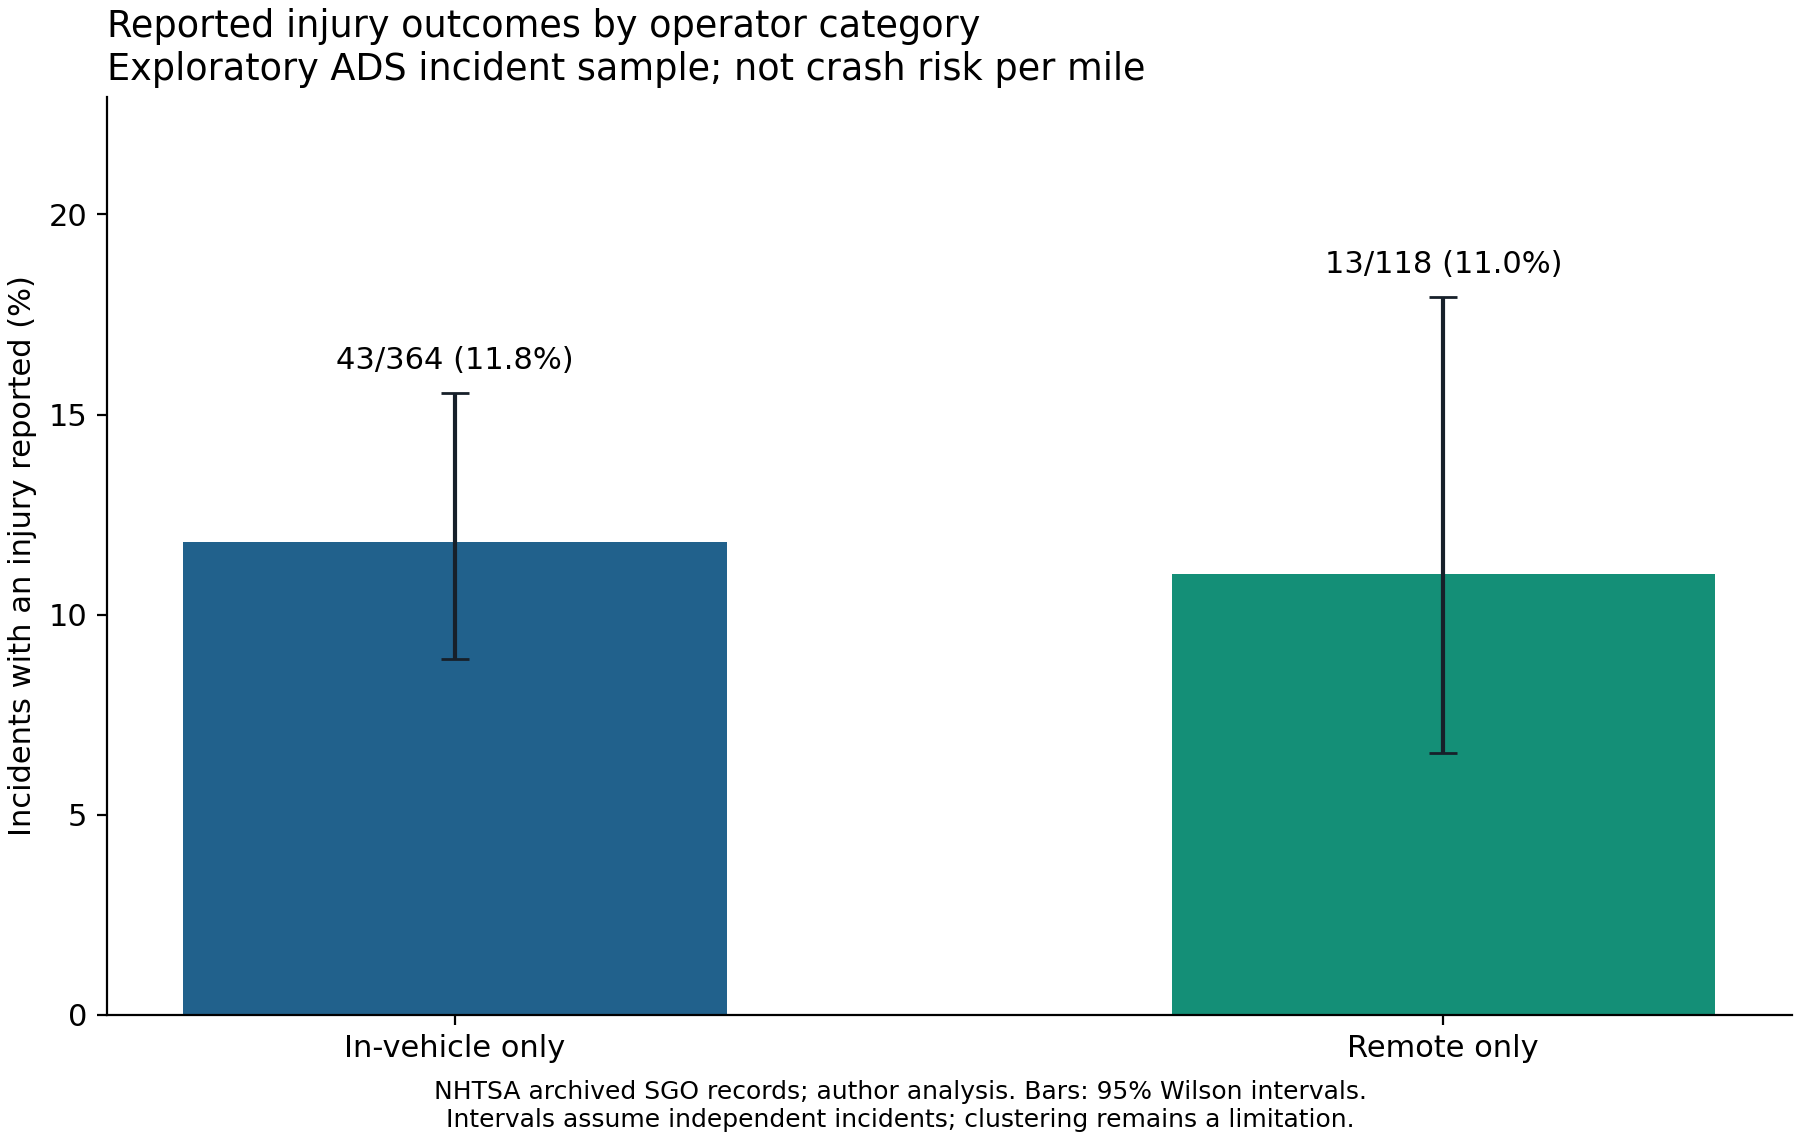

In [13]:
assert results["n"] == 482
assert abs(results["pearson_p_nominal"] - 0.8145480939536577) < 1e-10
assert results["minimum_expected_count"] >= 5
print("Verified sample and statistical calculation; causal safety claims are not established.")
display(Image(filename=str(NB_ROOT / "nhtsa/05_operator_category_injury.png")))


## 8 Interpretation and evidence-based recommendations
The final Uber window documents downward gaze but does not directly measure understanding, trust, workload or phone use. The NHTSA comparison is non-significant (p = .815); this does not demonstrate equivalence or show which operator arrangement is safer. Neither source measures the effects of a new safety intervention.

The evidence supports evaluating readiness monitoring, understandable transition information and protective vehicle responses together, including driver non-response. Proposed benefits require matched-scenario tests of comprehension, manoeuvre quality, separation and collision mitigation. The verified changes made here concern cleaning, traceability and statistical reporting.

## Original sources
- NTSB docket HWY18MH010 item 43 (recorder CSV) and item 42 (Payne, 2019, recorder interpretation): https://data.ntsb.gov/Docket?NTSBNumber=HWY18MH010
- NTSB accident report HAR-19/03: https://www.ntsb.gov/investigations/AccidentReports/Reports/HAR1903.pdf
- NHTSA archived ADS reports: https://static.nhtsa.gov/odi/ffdd/sgo-2021-01/Archive-2021-2025/SGO-2021-01_Incident_Reports_ADS.csv

A large row count from one driver is not an independent driver sample. No new driving simulation or participant study was conducted.

## 9 Results for the report
These short cells bring the main results together. Each output comes from the analysis above. The original data and the complete analysis remain available earlier in the notebook.

### How much data remained after cleaning
The numbers below use different units: raw rows and latest reports are report records; linked groups and the final sample are incident groups.

In [14]:
print(f"Original report rows: {len(raw):,}")
print(f"Latest report versions: {len(latest):,}")
print(f"Linked incident groups: {len(incidents):,}")
print("Incidents used:", len(sample))


Original report rows: 2,295
Latest report versions: 1,899
Linked incident groups: 1,520
Incidents used: 482


The final comparison uses 482 incident groups. Reducing the number of records removes superseded reports and applies the eligibility rules; it does not mean that the excluded incidents were unimportant.

In [15]:
operator_types = latest["Driver / Operator Type"]
print("Reports labelled None:", operator_types.eq("None").sum())
print("Reports with missing operator values:", operator_types.isna().sum())
print("Groups outside the selected categories:",
      audit["decisions"]["Operator category outside the two specified groups"])


Reports labelled None: 920
Reports with missing operator values: 0
Groups outside the selected categories: 958


None is a recorded operator category, not a blank field. Preserving it corrects the exclusion explanation. The in-vehicle-only versus remote-only comparison still contains 482 incident groups.

Downward gaze episodes: 23
Total downward gaze: 58.4 seconds
Median / maximum: 2.20 / 6.90 seconds


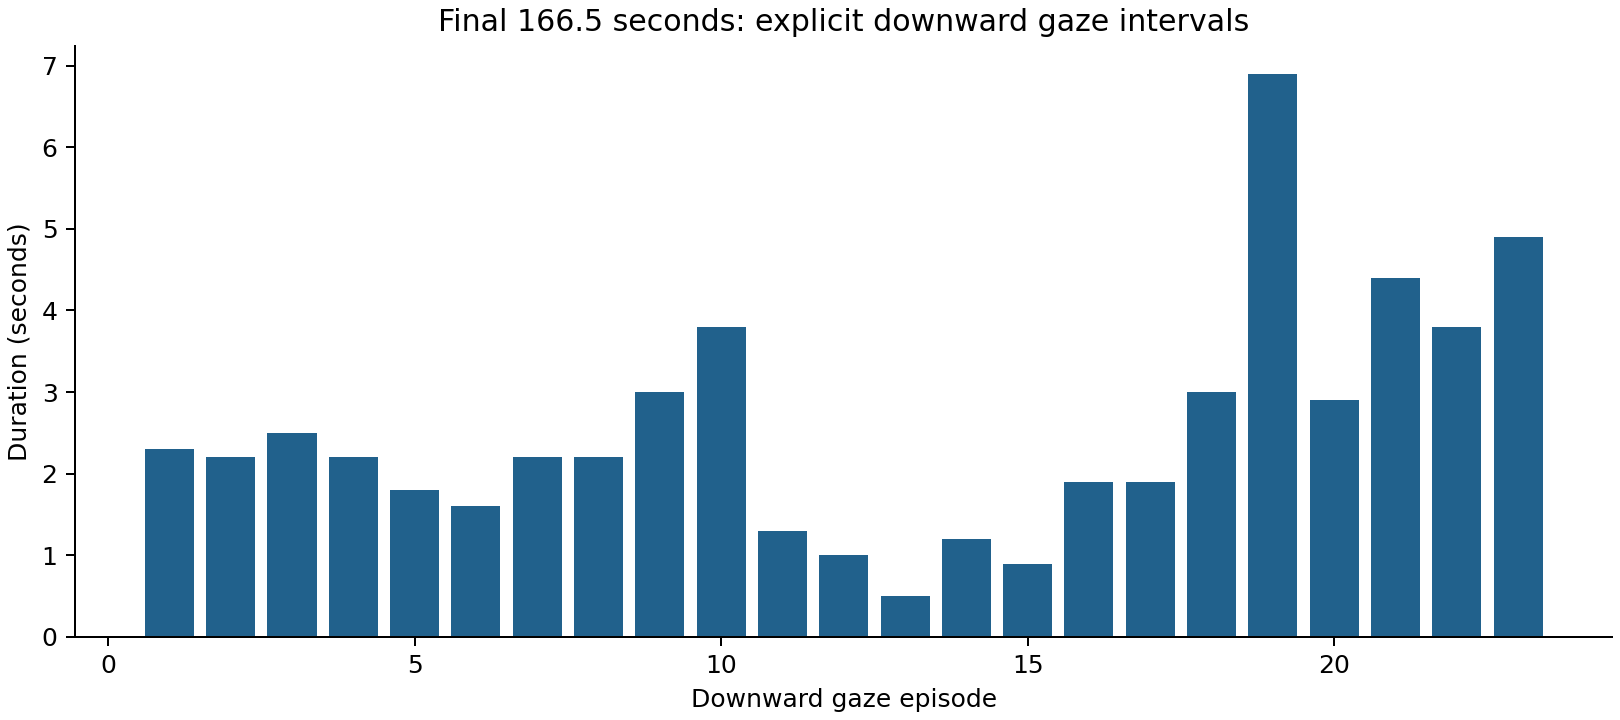

In [16]:
print("Downward gaze episodes:", window["episodes"])
print(f"Total downward gaze: {window['total_downward_s']:.1f} seconds")
print(f"Median / maximum: {window['median_s']:.2f} / {window['maximum_s']:.2f} seconds")
display(Image(filename="uber_tempe/Uber_Tempe_Analysis/03_final_window_glances.png"))


The longest episode is much longer than the median, so an average alone would hide some of the attention gaps. These data describe gaze direction. They do not show whether a warning or monitoring system would have prevented the collision.

In [17]:
counts = pd.crosstab(sample["operator_group"], sample["injury_outcome"])
chi2, p, df, expected = chi2_contingency(counts, correction=False)
v = np.sqrt(chi2 / counts.to_numpy().sum())
print(counts.to_string())
print(f"Pearson chi-square: {chi2:.3f}")
print(f"Degrees of freedom: {df}")
print(f"p-value: {p:.6f}")
print(f"Cramer's V: {v:.3f}")


injury_outcome   Injury reported  No injuries reported
operator_group                                        
In-vehicle only               43                   321
Remote only                   13                   105
Pearson chi-square: 0.055
Degrees of freedom: 1
p-value: 0.814548
Cramer's V: 0.011


The p-value is above .05, so this sample does not provide sufficient evidence of an association. This does not prove that the operator arrangements are equally safe, and it is not a comparison of crash rates per mile.

In [18]:
check = results["one_incident_per_identifiable_vehicle_sensitivity"]
print("Incidents after keeping one per identifiable vehicle:", check["n"])
print(f"Sensitivity p-value: {check['p_nominal']:.3f}")
print("Repeated vehicle identifier groups:",
      results["repeated_vehicle_identifier_groups"])


Incidents after keeping one per identifiable vehicle: 423
Sensitivity p-value: 0.767
Repeated vehicle identifier groups: 53


The result remains non-significant after this sensitivity check. Keeping one incident per identifiable vehicle addresses that source of repetition, but fleet differences and other confounding remain.

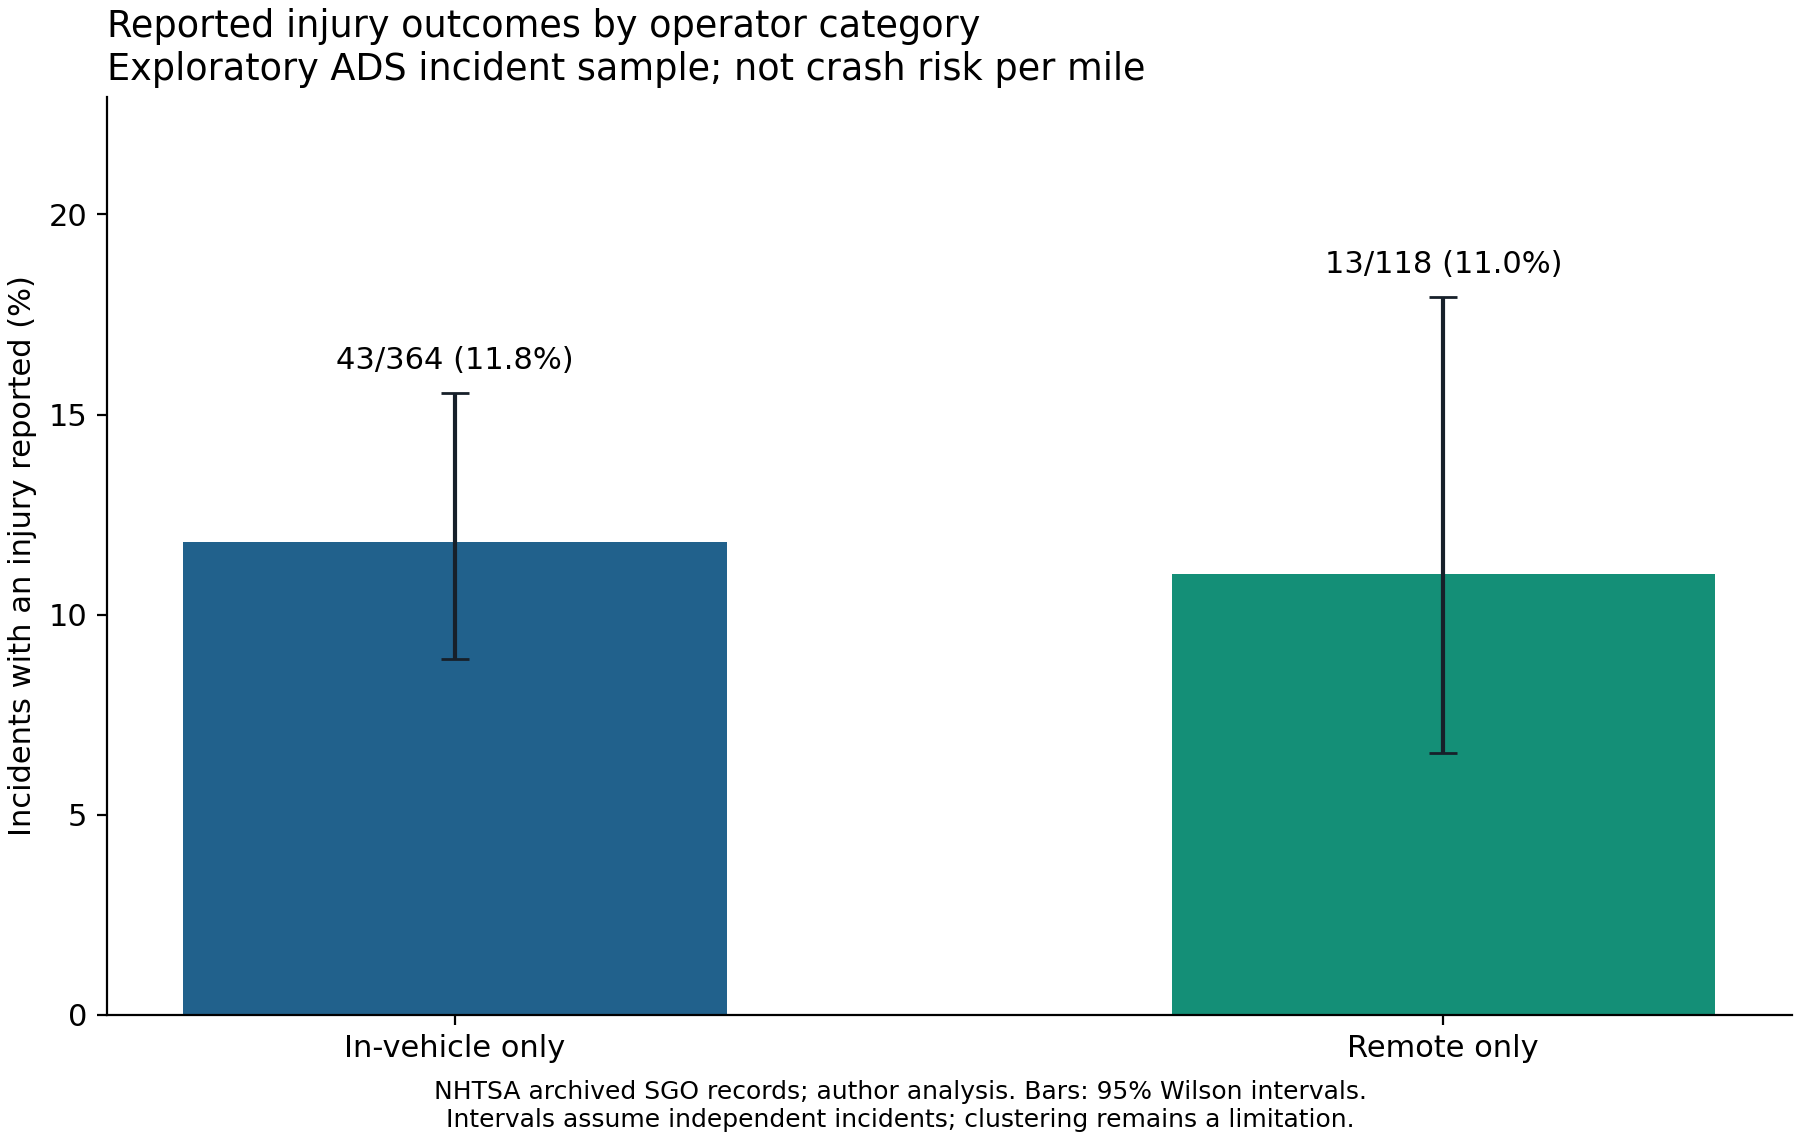

In [19]:
display(Image(filename=str(NB_ROOT / "nhtsa/05_operator_category_injury.png")))


The bars show injuries reported in 43 of 364 in-vehicle-only incidents and 13 of 118 remote-only incidents. The error bars show uncertainty under an independence assumption. They should not be used to claim that one arrangement causes fewer injuries.

## 10 Testing an earlier braking response

The accident evidence motivates this question; all numerical inputs below are illustrative assumptions. This one-dimensional model compares a 1.5 s delay with a 0.3 s delay. Both recognise the hazard at time zero. It tests braking timing only, not driver attention or Level 3 effectiveness. A fixed conflict line stays occupied. Braking starts instantly at constant deceleration. See `simulation/assumptions.json`.

In [20]:
import itertools, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
OUT = NB_ROOT / "simulation"
OUT.mkdir(exist_ok=True)
import math

def brake_outcome(speed_kmh, distance_m, delay_s, deceleration):
    """Point vehicle approaching a fixed conflict line on a level road."""
    if speed_kmh <= 0 or distance_m < 0 or delay_s < 0 or deceleration <= 0:
        raise ValueError("Use positive speed/deceleration and nonnegative distance/delay")
    v = speed_kmh / 3.6
    delay_distance = v * delay_s
    stopping_distance = delay_distance + v**2 / (2 * deceleration)
    clearance = distance_m - stopping_distance
    reaches_line = clearance < -1e-9
    if distance_m <= delay_distance:
        impact_speed = v
    else:
        impact_speed = math.sqrt(max(0, v**2 - 2 * deceleration * (distance_m - delay_distance)))
    return {"stopping_distance_m": stopping_distance,
            "clearance_m": clearance,
            "impact_speed_kmh": impact_speed * 3.6,
            "reaches_conflict_line": reaches_line}

brake = brake_outcome

In [21]:
rows=[]
for distance in [35,50,70]:
    for label,delay in [('Delayed response',1.5),('Earlier response',0.3)]:
        rows.append(dict(scenario=label,speed_kmh=72,distance_m=distance,delay_s=delay,deceleration_m_s2=6,**brake(72,distance,delay,6)))
examples=pd.DataFrame(rows);examples.to_csv(OUT/'example_results.csv',index=False)
grid=[]
for speed,distance,a in itertools.product([30,40,50,60,70],[*range(20,101,5)],[3,4.5,6,7.5]):
    b=brake(speed,distance,1.5,a); e=brake(speed,distance,0.3,a)
    grid.append(dict(speed_kmh=speed,distance_m=distance,deceleration_m_s2=a,baseline_impact_kmh=b['impact_speed_kmh'],earlier_impact_kmh=e['impact_speed_kmh'],baseline_reaches_line=b['reaches_conflict_line'],earlier_reaches_line=e['reaches_conflict_line'],stopping_distance_reduction_m=b['stopping_distance_m']-e['stopping_distance_m']))
grid=pd.DataFrame(grid);grid.to_csv(OUT/'scenario_grid.csv',index=False)
delays=pd.DataFrame([dict(delay_s=d,**brake(72,50,float(d),6)) for d in np.linspace(0,2.5,101)])
delays.to_csv(OUT/'delay_sensitivity.csv',index=False)
# Checks cover known solutions and boundary cases, independently of the scenario grid.
assert math.isclose(brake(36,100,0,5)['stopping_distance_m'],10)
assert math.isclose(brake(36,100,1,5)['stopping_distance_m'],20)
assert math.isclose(brake(36,5,1,5)['impact_speed_kmh'],36)
assert brake(36,10,0,5)['impact_speed_kmh']==0
assert not brake(36,10,0,5)['reaches_conflict_line']
assert (grid.earlier_impact_kmh <= grid.baseline_impact_kmh+1e-9).all()
assert np.allclose(grid.stopping_distance_reduction_m,grid.speed_kmh/3.6*1.2)
summary={'grid_scenarios':len(grid),'baseline_line_reached':int(grid.baseline_reaches_line.sum()),'earlier_line_reached':int(grid.earlier_reaches_line.sum()),'additional_stops_before_line':int((grid.baseline_reaches_line & ~grid.earlier_reaches_line).sum()),'checks_passed':7,'meaning':'Deterministic scenario counts, not accident probabilities or independent observations.'}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(8,3.5))
for label,color in [('Delayed response','#24658b'),('Earlier response','#078b71')]:
    delay=1.5 if label=='Delayed response' else .3
    t=np.linspace(0,5,501);v=20.;bt=np.maximum(0,t-delay);bt=np.minimum(bt,v/6)
    x=v*np.minimum(t,delay)+v*bt-3*bt**2
    ax.plot(t,x,label=f'{label} ({delay:.1f} s)',color=color,lw=2)
ax.axhline(50,color='black',ls='--',label='Fixed conflict line (50 m)')
ax.set(xlabel='Time from assumed hazard recognition (s)',ylabel='Distance travelled (m)',title='Modelled braking at 72 km/h and 6 m/s²')
ax.legend(fontsize=9,loc='lower right');fig.tight_layout();fig.savefig(OUT/'01_braking_comparison.png',dpi=180);plt.close(fig)
fig,axs=plt.subplots(1,2,figsize=(9,3.5))
axs[0].plot(delays.delay_s,delays.stopping_distance_m,color='#24658b');axs[0].axhline(50,color='black',ls='--');axs[0].set(ylabel='Stopping distance (m)',xlabel='Delay before braking (s)')
axs[1].plot(delays.delay_s,delays.impact_speed_kmh,color='#9a4b18');axs[1].set(ylabel='Speed at conflict line (km/h)',xlabel='Delay before braking (s)')
fig.suptitle('Delay sensitivity with other assumptions held fixed');fig.tight_layout();fig.savefig(OUT/'02_delay_sensitivity.png',dpi=180);plt.close(fig)
assumptions={'source':'NTSB (2019), HAR-19/03, section 2.2.1, printed pp. 40–41. https://www.ntsb.gov/investigations/AccidentReports/Reports/HAR1903.pdf','source_role':'Motivates examining braking delay. No event parameter below is a calibrated reconstruction.','illustrative_example':{'speed_kmh':72,'distances_m':[35,50,70],'baseline_delay_s':1.5,'earlier_delay_s':0.3,'constant_deceleration_m_s2':6},'grid':{'speed_kmh':[30,40,50,60,70],'distance_m':list(range(20,101,5)),'constant_deceleration_m_s2':[3,4.5,6,7.5]},'limitations':['Assumed recognition at time zero in both conditions; detection and prediction failures are not simulated.','Fixed conflict line remains occupied; no pedestrian trajectory or evasive steering.','Instantaneous constant braking after delay; no brake build-up, jerk, gradient or tyre model.','No empirical human response distribution, driver-monitoring benefit or Level 2 versus Level 3 effectiveness test.','Grid counts are design scenarios, not probabilities; no chi-square or p-value for synthetic cases.']}
(OUT/'assumptions.json').write_text(json.dumps(assumptions,indent=2))
(OUT/'README.md').write_text('''# Illustrative braking simulation
This is a deterministic one-dimensional kinematic model, not an Uber crash reconstruction, CARLA model or participant driving simulator.
All numerical scenario inputs are modelling assumptions. NTSB HAR-19/03 motivates studying delay; its event timings are not substituted as human response times.

Stopping distance = v × delay + v² / (2a), with speed v in m/s and constant deceleration a in m/s². The vehicle coasts during the delay and then brakes. When the conflict line is reached during the delay, impact speed equals initial speed. Otherwise speed follows v² - 2a × braking distance, clipped at zero. Clearance is the hypothetical final stopping position relative to the line; a negative value is an overshoot, not a physically observed post-impact path.

Run the Simulation section of analysis.ipynb to regenerate all CSV results and charts. Every grid case uses the same inputs for both responses except delay. See assumptions.json for provenance and limits. Grid counts are not crash probabilities. Earlier braking is mechanically beneficial under these assumptions; this does not validate detection, warnings, driver monitoring, or actual Level 3 safety.
''')

print("Simulation checks passed:", summary["checks_passed"])
print(examples[["scenario", "distance_m", "stopping_distance_m", "impact_speed_kmh"]].round(2).to_string(index=False))
print(json.dumps(summary, indent=2))

Simulation checks passed: 7
        scenario  distance_m  stopping_distance_m  impact_speed_kmh
Delayed response          35                63.33             66.38
Earlier response          35                39.33             25.96
Delayed response          50                63.33             45.54
Earlier response          50                39.33              0.00
Delayed response          70                63.33              0.00
Earlier response          70                39.33              0.00
{
  "grid_scenarios": 340,
  "baseline_line_reached": 103,
  "earlier_line_reached": 45,
  "additional_stops_before_line": 58,
  "checks_passed": 7,
  "meaning": "Deterministic scenario counts, not accident probabilities or independent observations."
}


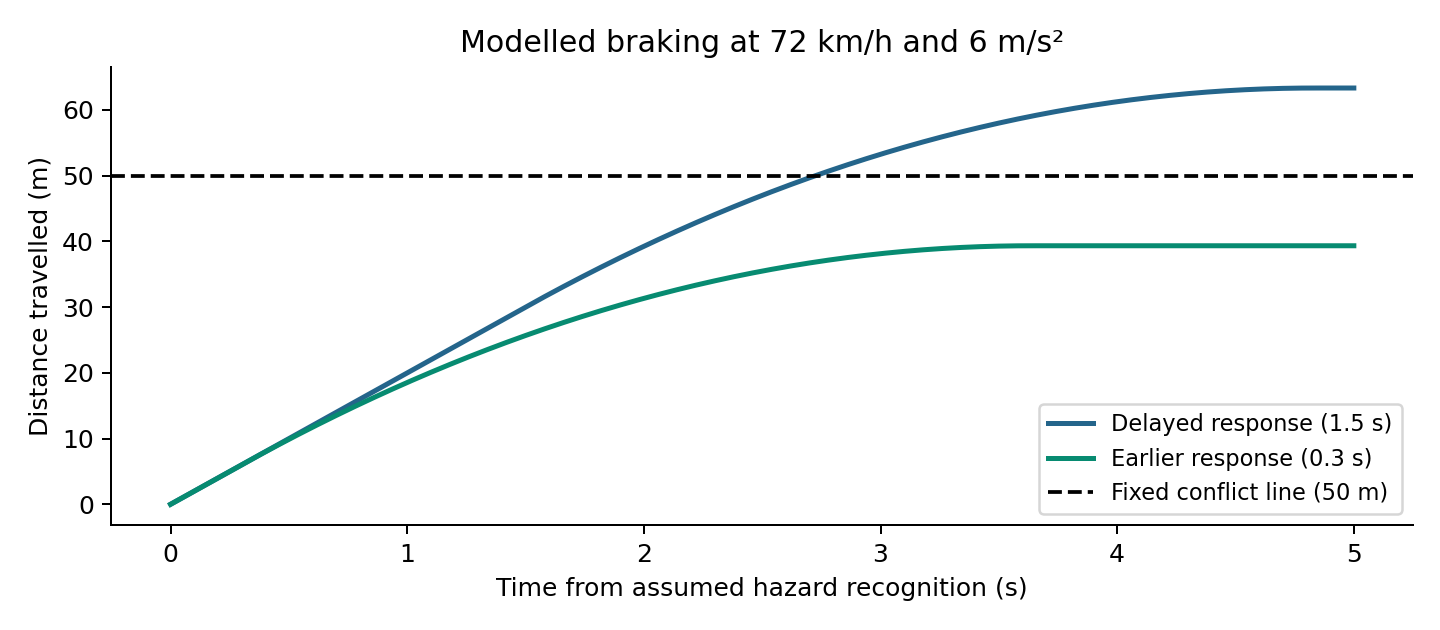

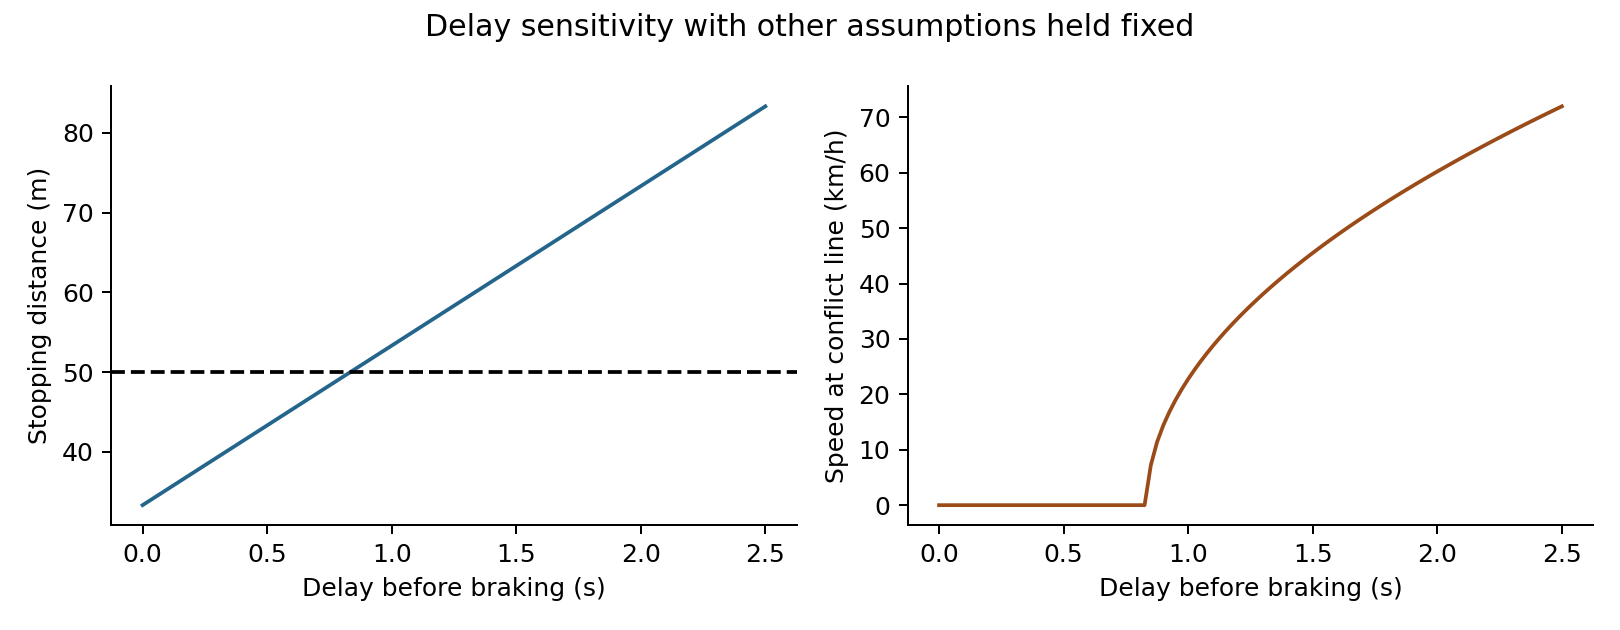

In [22]:
display(Image(filename=str(OUT / "01_braking_comparison.png")))
display(Image(filename=str(OUT / "02_delay_sensitivity.png")))

### What this result means
Reducing the assumed delay removes 1.2 × initial speed metres from stopping distance. At 72 km/h that is 24 m. The benefit follows from the model equations; the simulation illustrates it rather than independently validating a new technology. At short distances both responses can still reach the conflict line. Test perception, brake actuation, false activations and human readiness separately before drawing real-world conclusions. Scenario counts are not probabilities, and synthetic scenarios are not used in the observational chi-square test.